# 07MIAR - Redes Neuronales y Deep Learning: Proyecto de programación "*Deep Vision in classification tasks*"


## Índice
1. **Carga del conjunto de datos.**
2. **Inspección y análisis del conjunto de datos.**
3. **Acondicionamiento y preprocesamiento de los datos.**
4. **Diseño de la arquitectura de la red neuronal y entrenamiento del modelo.**
5. **Monitorización del proceso de entrenamiento y toma de decisiones a partir de los resultados obtenidos.**
6. **Evaluación del modelo y análisis de los resultados.**

## 1. Carga del conjunto de datos

Desde Kaggle, obtenemos el dataset Stanford Dogs para clasificación. Para descargarlo usamos `kagglehub` que descarga y descomprime el dataset automáticamente. 

In [6]:
import kagglehub

path = kagglehub.dataset_download("jessicali9530/stanford-dogs-dataset")
print("Path to dataset files:", path)

100%|██████████| 750M/750M [00:18<00:00, 42.3MB/s] 

Extracting files...


Path to dataset files: C:\Users\usuario\.cache\kagglehub\datasets\jessicali9530\stanford-dogs-dataset\versions\2


## 2. Inspección y análisis del conjunto de datos

In [53]:
import os
import matplotlib.pyplot as plt
import cv2

Para justificar la elección del dataset de imágenes para clasificación, describimos las características principales del dataset.  Una vez descargado, vemos cómo están organizados los archivos. Se tienen dos carpetas `annotations` y `images`. La carpeta `images` contiene una subcarpeta por cada raza de perro. En total hay 120 razas de perro.

In [ ]:
print(os.listdir(path))

['annotations', 'images']


In [27]:
img_dir_path = os.path.join(path, "images")
print(os.listdir(img_dir_path))

['Images']


In [40]:
img_dir = os.path.join(img_dir_path, "Images")
print(os.listdir(img_dir)[:5])
total_razas = sorted(os.listdir(img_dir))
print("Número de carpetas:", len(total_razas))

['n02085620-Chihuahua', 'n02085782-Japanese_spaniel', 'n02085936-Maltese_dog', 'n02086079-Pekinese', 'n02086240-Shih-Tzu']
Número de carpetas: 120


Al acceder al contenido de una carpeta, una raza, vemos que se encuentran las imágenes de cada una en formato `.jpg`. 

In [52]:
print(os.listdir(os.path.join(img_dir, "n02085620-Chihuahua"))[:5])

['n02085620_10074.jpg', 'n02085620_10131.jpg', 'n02085620_10621.jpg', 'n02085620_1073.jpg', 'n02085620_10976.jpg']


Veamos cuántas imágenes hay en cada carpeta por raza. Con ello también se obtiene el número total de imágenes del dataset. También obtenemos el mínimo número de imágenes por raza y el máximo. Dibujamos una gráfica de barras por raza para ver la distribución de las clases. COMPLETAR(equilibrio clases)

Número total de imágenes: 20580
Imágenes por raza con mínimo: 148 y máximo: 252


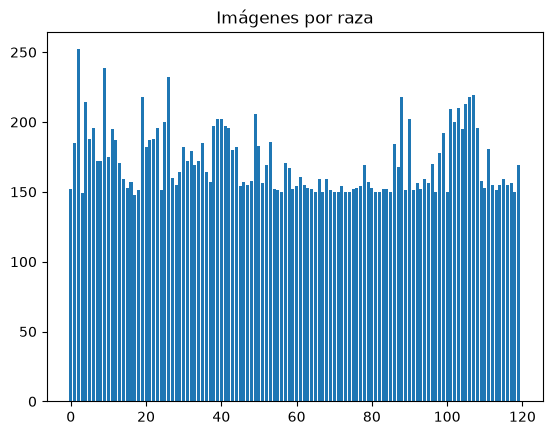

In [51]:
conteo_por_raza = []
for r in total_razas:
    a = len(os.listdir(os.path.join(img_dir, r)))
    conteo_por_raza.append(a)
total_imagenes = sum(conteo_por_raza)
print("Número total de imágenes:", total_imagenes)
print("Imágenes por raza con mínimo:", min(conteo_por_raza), "y máximo:", max(conteo_por_raza))
plt.bar(range(len(conteo_por_raza)), conteo_por_raza)
plt.title("Imágenes por raza")
plt.show()

También vemos las dimensiones de las imágenes. Para ello leemos el ancho y el alto de cada imagen y los representamos en un mapa de calor, donde las zonas más intensas indican los tamaños más frecuentes. COMPLETAR(mismo tamaño para la red)

Ancho: mínimo 97 y máximo 3264
Alto: mínimo 100 y máximo 2562


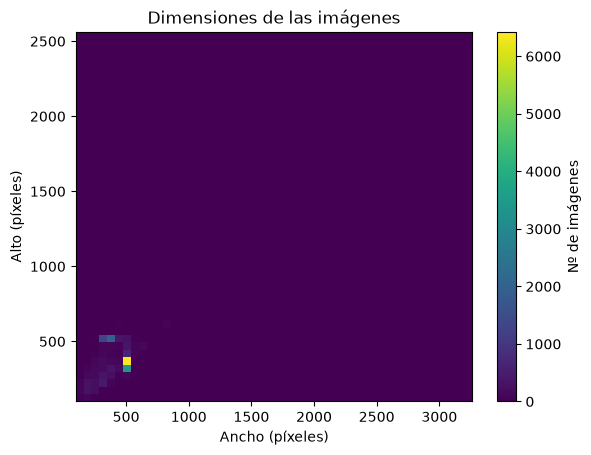

In [54]:
anchos = []
altos = []
for r in total_razas:
    for foto in os.listdir(os.path.join(img_dir, r)):
        img = cv2.imread(os.path.join(img_dir, r, foto))
        h, w, c = img.shape
        anchos.append(w)
        altos.append(h)

print("Ancho: mínimo", min(anchos), "y máximo", max(anchos))
print("Alto: mínimo", min(altos), "y máximo", max(altos))

plt.hist2d(anchos, altos, bins=50, cmap="viridis")
plt.colorbar(label="Nº de imágenes")
plt.xlabel("Ancho (píxeles)")
plt.ylabel("Alto (píxeles)")
plt.title("Dimensiones de las imágenes")
plt.show()

COMPLETAR

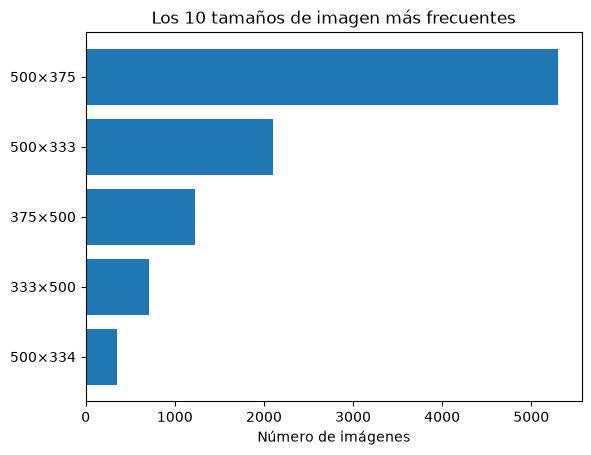

Hay 4542 tamaños distintos


In [60]:
from collections import Counter

tamanos = Counter(zip(anchos, altos))
top = tamanos.most_common(5)[::-1]

wh = [f"{w}×{h}" for (w, h), n in top]
freq = [n for (w, h), n in top]

plt.barh(wh, freq)
plt.xlabel("Número de imágenes")
plt.title("Los 10 tamaños de imagen más frecuentes")
plt.show()

print("Hay", len(tamanos), "tamaños distintos")

COMPLETAR

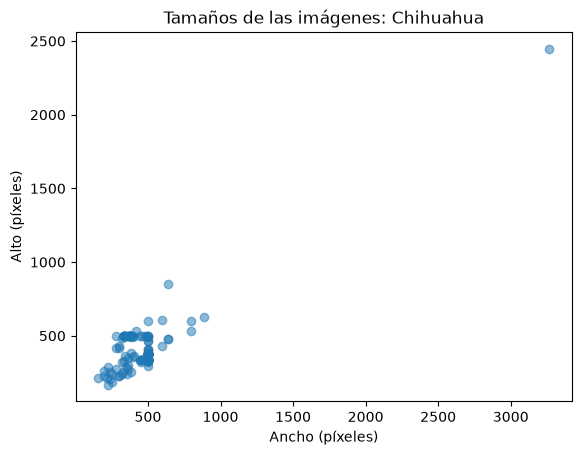

In [62]:
raza = "n02085620-Chihuahua"

anchos_raza = []
altos_raza = []
for foto in os.listdir(os.path.join(img_dir, raza)):
    h, w, _ = cv2.imread(os.path.join(img_dir, raza, foto)).shape
    anchos_raza.append(w)
    altos_raza.append(h)

plt.scatter(anchos_raza, altos_raza, alpha=0.5)
plt.xlabel("Ancho (píxeles)")
plt.ylabel("Alto (píxeles)")
plt.title("Tamaños de las imágenes: Chihuahua")
plt.show()

Por último, la carpeta `annotations` del dataset contiene una subcarpeta `Annotation`, organizada igual que `images`, es decir, con una carpeta por raza. Dentro de cada una hay un archivo por foto, con el mismo nombre que la imagen pero sin la extensión `.jpg`.

In [36]:
ann_dir_path = os.path.join(path, "annotations")
print(os.listdir(ann_dir_path))
ann_dir = os.path.join(ann_dir_path, "Annotation")
print(os.listdir(ann_dir)[:5])
print(os.listdir(os.path.join(ann_dir, "n02085620-Chihuahua"))[:5])

['Annotation']
['n02085620-Chihuahua', 'n02085782-Japanese_spaniel', 'n02085936-Maltese_dog', 'n02086079-Pekinese', 'n02086240-Shih-Tzu']
['n02085620_10074', 'n02085620_10131', 'n02085620_10621', 'n02085620_1073', 'n02085620_10976']


Al abrir uno de ellos (`n02085620_10074`, de la carpeta Chihuahua) vemos que es un archivo de texto con información sobre la foto con el nombre de la raza del perro, el tamaño de la imagen y una caja (`bndbox`) que marca dónde aparece el perro dentro de la foto.

Esta información sería útil para un problema de detección, pero nosotros solo queremos clasificar la raza, así que trabajaremos únicamente con las imágenes. Además, vemos que las fotos provienen de **ImageNet**, por lo que lo tendremos en cuenta más adelante al usar redes preentrenadas, ya que se entrenaron con ese mismo conjunto de datos.

In [42]:
with open(os.path.join(ann_dir, "n02085620-Chihuahua", "n02085620_10074")) as f:
    print(f.read())

<annotation>
	<folder>02085620</folder>
	<filename>n02085620_10074</filename>
	<source>
		<database>ImageNet database</database>
	</source>
	<size>
		<width>333</width>
		<height>500</height>
		<depth>3</depth>
	</size>
	<segment>0</segment>
	<object>
		<name>Chihuahua</name>
		<pose>Unspecified</pose>
		<truncated>0</truncated>
		<difficult>0</difficult>
		<bndbox>
			<xmin>25</xmin>
			<ymin>10</ymin>
			<xmax>276</xmax>
			<ymax>498</ymax>
		</bndbox>
	</object>
</annotation>
